In [1]:
# Import libraries required for model evaluation and comparison
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the directories containing the saved experiment results
base_dir = "../models/experiments"

lstm_dir = os.path.join(base_dir, "lstm_baseline")
bilstm_dir = os.path.join(base_dir, "bilstm")
attention_dir = os.path.join(base_dir, "attention_bilstm")

# Load the test evaluation results of all three models
lstm_results = pd.read_csv(os.path.join(lstm_dir, "test_results.csv"))
bilstm_results = pd.read_csv(os.path.join(bilstm_dir, "test_results.csv"))
attention_results = pd.read_csv(os.path.join(attention_dir, "test_results.csv"))

# Display the saved test results to verify successful loading
print("LSTM Test Results:")
display(lstm_results)

print("BiLSTM Test Results:")
display(bilstm_results)

print("Attention-BiLSTM Test Results:")
display(attention_results)

LSTM Test Results:


,Metric,Score
0,Test Accuracy,0.819209
1,Macro Precision,0.719668
2,Macro Recall,0.696357
3,Macro F1-score,0.697694
4,Weighted F1-score,0.815803


BiLSTM Test Results:


,Metric,Score
0,Test Accuracy,0.818402
1,Macro Precision,0.772226
2,Macro Recall,0.669828
3,Macro F1-score,0.682051
4,Weighted F1-score,0.808884


Attention-BiLSTM Test Results:


,Metric,Score
0,Test Accuracy,0.821630
1,Macro Precision,0.685882
2,Macro Recall,0.656435
3,Macro F1-Score,0.664431
4,Weighted F1-Score,0.809502


In [2]:
# Create a function to extract and standardize metrics from each result file
def extract_metrics(results):
    metrics = results.set_index("Metric")["Score"]

    # Normalize metric names to handle capitalization differences
    metrics.index = metrics.index.str.lower().str.strip()

    return metrics

# Extract metrics for all three models
lstm_metrics = extract_metrics(lstm_results)
bilstm_metrics = extract_metrics(bilstm_results)
attention_metrics = extract_metrics(attention_results)

# Combine the metrics into one comparison DataFrame
model_comparison = pd.DataFrame({
    "LSTM": lstm_metrics,
    "BiLSTM": bilstm_metrics,
    "Attention-BiLSTM": attention_metrics
})

# Rename rows for better presentation
model_comparison.index = [
    "Test Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score",
    "Weighted F1-score"
]

# Display the consolidated comparison table
display(model_comparison.round(4))

# Save the consolidated comparison results
model_comparison.to_csv(
    os.path.join(base_dir, "model_test_comparison.csv")
)

print("Model comparison table saved successfully!")

,LSTM,BiLSTM,Attention-BiLSTM
Test Accuracy,0.8192,0.8184,0.8216
Macro Precision,0.7197,0.7722,0.6859
Macro Recall,0.6964,0.6698,0.6564
Macro F1-score,0.6977,0.6821,0.6644
Weighted F1-score,0.8158,0.8089,0.8095


Model comparison table saved successfully!


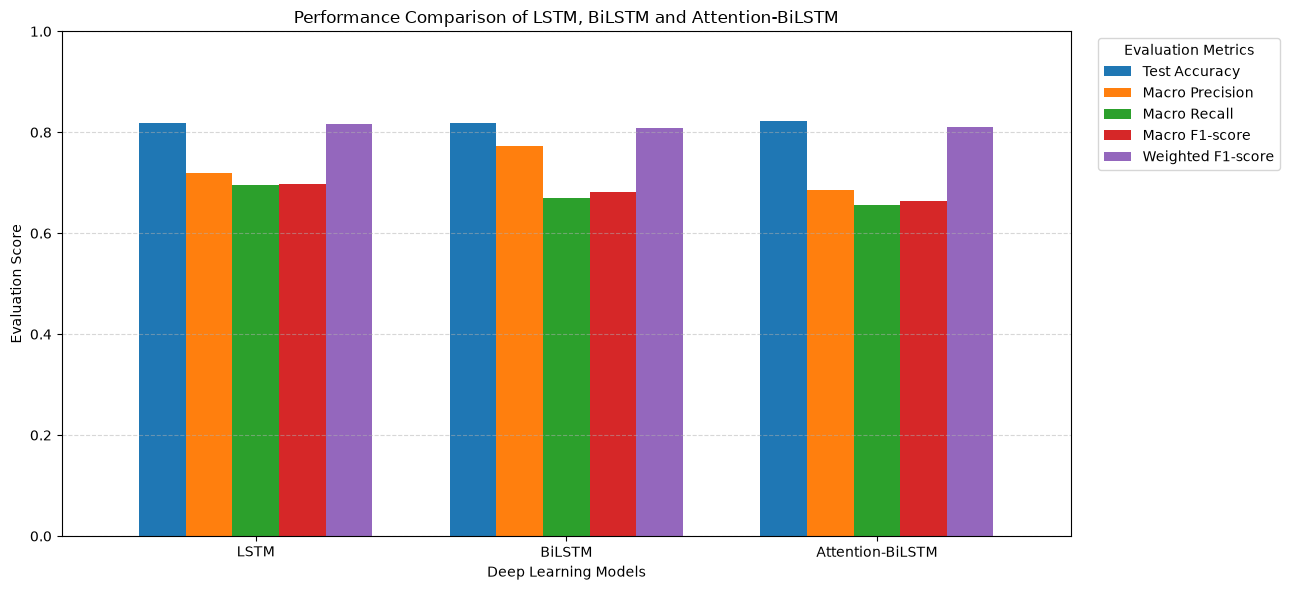

In [3]:
# Create a bar chart to compare the performance of all three models
metrics_to_plot = [
    "Test Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score",
    "Weighted F1-score"
]

# Transpose the comparison DataFrame for plotting
plot_data = model_comparison.loc[metrics_to_plot].T

# Plot the comparison
ax = plot_data.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.75
)

# Add chart labels and formatting
plt.title("Performance Comparison of LSTM, BiLSTM and Attention-BiLSTM")
plt.xlabel("Deep Learning Models")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display the chart
plt.tight_layout()
plt.show()


In [5]:
# Load the validation classification reports of all three models
lstm_report = pd.read_csv(
    os.path.join(lstm_dir, "validation_classification_report.csv"),
    index_col=0
)

bilstm_report = pd.read_csv(
    os.path.join(bilstm_dir, "validation_classification_report.csv"),
    index_col=0
)

attention_report = pd.read_csv(
    os.path.join(attention_dir, "validation_classification_report.csv"),
    index_col=0
)

# Define the 12 complaint categories in the original label order
categories = [
    "Animal Management",
    "Civic Infrastructure and Encroachment",
    "Drainage and Sewerage",
    "Electricity and Utilities",
    "Environment and Public Spaces",
    "Public Safety",
    "Public Sanitation",
    "Road Infrastructure",
    "Street Lighting",
    "Traffic and Transport",
    "Waste Management",
    "Water Supply"
]

# Compare the validation F1-scores across all three models
class_f1_comparison = pd.DataFrame({
    "LSTM": lstm_report.loc[categories, "f1-score"],
    "BiLSTM": bilstm_report.loc[categories, "f1-score"],
    "Attention-BiLSTM": attention_report.loc[categories, "f1-score"]
})

# Display the per-class comparison
display(class_f1_comparison.round(4))

,LSTM,BiLSTM,Attention-BiLSTM
Animal Management,0.9402,0.9402,0.9202
Civic Infrastructure and Encroachment,0.3333,0.2400,0.2609
Drainage and Sewerage,0.5630,0.5527,0.5618
Electricity and Utilities,0.7952,0.8101,0.7500
Environment and Public Spaces,0.6311,0.5888,0.6509
Public Safety,0.0606,0.0000,0.1212
Public Sanitation,0.8382,0.7939,0.7971
Road Infrastructure,0.8423,0.8382,0.8439
Street Lighting,0.8878,0.8759,0.8645
Traffic and Transport,0.7177,0.7548,0.7239


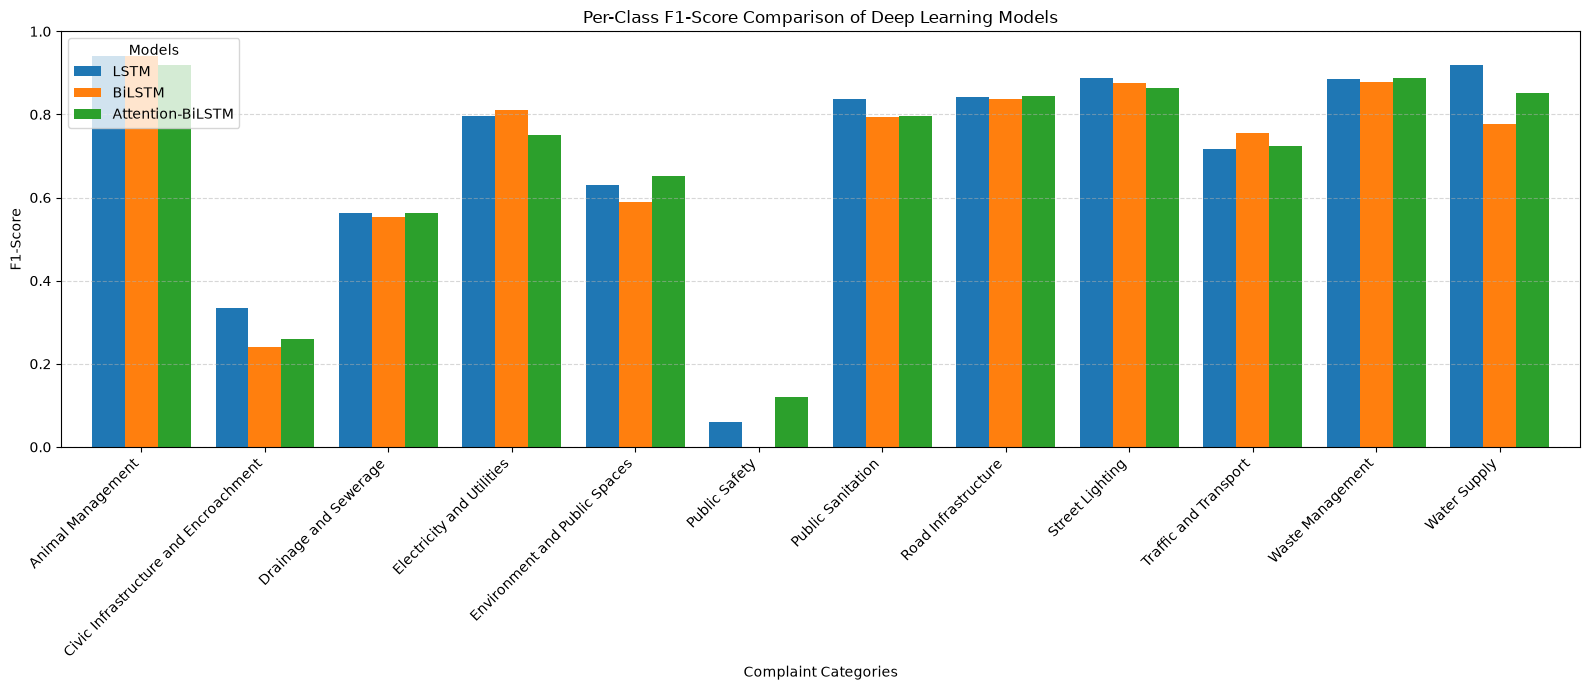

In [6]:
# Plot per-class F1-score comparison for all three models
ax = class_f1_comparison.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

# Add chart title and axis labels
plt.title("Per-Class F1-Score Comparison of Deep Learning Models")
plt.xlabel("Complaint Categories")
plt.ylabel("F1-Score")

# Format the chart for readability
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Models")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display the comparison chart
plt.tight_layout()
plt.show()

In [7]:
# Save the per-class F1-score comparison
class_f1_comparison.to_csv(
    os.path.join(base_dir, "per_class_f1_comparison.csv")
)

# Identify the model with the highest Macro F1-score
best_model = model_comparison.loc["Macro F1-score"].idxmax()

# Identify the best model for each complaint category
best_model_per_class = class_f1_comparison.idxmax(axis=1)

# Create a summary of the final model evaluation
print("FINAL MODEL EVALUATION SUMMARY")
print("-----------------------------------")

print("\nOverall Best Model:", best_model)

print(
    "Highest Macro F1-score:",
    round(model_comparison.loc["Macro F1-score", best_model], 4)
)

print("\nBest Model for Each Complaint Category:")
display(best_model_per_class.to_frame(name="Best Model"))

# Save the best model per category
best_model_per_class.to_csv(
    os.path.join(base_dir, "best_model_per_category.csv")
)

print("\nFinal evaluation files saved successfully!")

FINAL MODEL EVALUATION SUMMARY
-----------------------------------

Overall Best Model: LSTM
Highest Macro F1-score: 0.6977

Best Model for Each Complaint Category:


,Best Model
Animal Management,LSTM
Civic Infrastructure and Encroachment,LSTM
Drainage and Sewerage,LSTM
Electricity and Utilities,BiLSTM
Environment and Public Spaces,Attention-BiLSTM
Public Safety,Attention-BiLSTM
Public Sanitation,LSTM
Road Infrastructure,Attention-BiLSTM
Street Lighting,LSTM
Traffic and Transport,BiLSTM



Final evaluation files saved successfully!
